Graph out the frequency and rythm of the steps in a long jump / triple jump approach using YOLO pose to track the athlete.

Import

In [83]:
%reload_ext autoreload
%autoreload 2


import cv2
import numpy as np
from ultralytics import YOLO
import os
import pandas as pd
import matplotlib.ticker as ticker
from scipy.signal import find_peaks 
from scipy.signal import savgol_filter

from longJump import tracking

from longJump import config
import importlib
importlib.reload(config)


from longJump.config import ROOT, PATHS, DETECTION, ATHLETE, TRACKING
from longJump.video import Video
from longJump import visualization
from longJump.athlete import Athlete
from longJump import detection



Load Image / Video

In [84]:
videoName = "Acceleration4"

video_path = str(ROOT / PATHS["videos"] / (videoName + ".mp4"))
save_path = str(ROOT / PATHS["output"] / (videoName + ".mp4"))
model_path = str(ROOT / PATHS["model"])
tracker_path = str(ROOT / PATHS["tracker"])


video = Video(video_path)



Run model to detect the person 

conf=0.25: Minimum confidence for detections.
iou=0.45: IoU threshold for non-maximum suppression.
classes=[0]: Detects only the “person” class (COCO ID 0).
device=’cuda:0': Uses GPU for inference.
half=True: Uses half-precision (FP16) for speed.
verbose=False: Suppresses detailed logs.

In [85]:

pose_results = tracking.RunTrackingPose(model_path, tracker_path, video_path, conf=TRACKING["conf_pose"], iou=TRACKING["iou_pose"],imgsz=TRACKING["imgsz_pose"])

bounding_boxes_df, video_keypoints_df = tracking.ProcessTrackingResults(pose_results)

# video_keypoints_df = tracking.InterpolateLowConfidenceAnkles(video_keypoints_df, TRACKING["minimum_confidence_threshold"])


WARNING 'source' is missing. Using 'source=C:\Users\ekrik\anaconda3\envs\jumpCV\Lib\site-packages\ultralytics\assets'.


DETECTING THE ATHLETE

Add up the absolute value of ((hip position - ankle position) - (last frames hip position - last frames ankle position))/ total number of frames that person appear

In [86]:
athlete_id = -1
mostMovement = 0

video_keypoints_df = video_keypoints_df.sort_values(by=["person_id", "frame"]) # sort by frame and person_id

for pid in video_keypoints_df["person_id"].unique():
    anklePositions = video_keypoints_df.loc[video_keypoints_df["person_id"] == pid, ['left_y', "left_hip_y"]]
    if (len(anklePositions) < video.fps):
        continue # Discard ppl not on frame for more than 30 frames
    
    totalMovement = (anklePositions["left_hip_y"] - anklePositions["left_y"]).abs().diff().abs().sum() # total the movement of the ankle between frames, because the athlete probably has a cyclical motion with lots of ankle movement, while spectators don't


    if (totalMovement.item() > mostMovement):
        mostMovement = totalMovement.item()
        athlete_id = pid
print(athlete_id)


video_keypoints_df

2


,frame,person_id,left_x,left_y,right_x,right_y,left_hip_x,left_hip_y,right_hip_x,right_hip_y,...,right_shoulder_x,right_shoulder_y,left_conf,right_conf,left_hip_conf,right_hip_conf,left_knee_conf,right_knee_conf,left_shoulder_conf,right_shoulder_conf
0,0,1,1675.0,525.50,1638.0,528.00,1676.0,437.75,1649.0,436.25,...,1648.0,370.50,0.986328,0.984375,0.992188,0.989746,0.990723,0.986328,0.988281,0.981934
3,1,1,1677.0,525.50,1640.0,529.50,1676.0,438.25,1648.0,436.75,...,1648.0,371.00,0.985840,0.983887,0.992188,0.989746,0.991211,0.986816,0.989258,0.983398
6,2,1,1678.0,525.50,1641.0,529.50,1674.0,438.75,1647.0,437.25,...,1647.0,371.50,0.984375,0.984375,0.992188,0.989258,0.989746,0.986328,0.989258,0.982422
9,3,1,1679.0,523.50,1642.0,530.50,1674.0,438.50,1646.0,437.25,...,1646.0,370.50,0.983887,0.984863,0.992676,0.989746,0.988770,0.985840,0.989746,0.982422
12,4,1,1678.0,520.00,1643.0,531.00,1674.0,438.75,1645.0,437.50,...,1643.0,370.50,0.983398,0.983887,0.993164,0.990234,0.987793,0.985352,0.991211,0.983887
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
492,166,3,1767.0,452.00,1693.0,446.00,1748.0,368.75,1724.0,366.50,...,1723.0,301.00,0.982422,0.979492,0.995605,0.980957,0.989746,0.968262,0.995117,0.936035
494,167,3,1818.0,451.00,1742.0,450.25,1795.0,368.25,1771.0,366.25,...,1772.0,300.50,0.983887,0.982422,0.995117,0.980469,0.988281,0.966797,0.993652,0.923828
496,168,3,1871.0,452.25,1792.0,452.50,1843.0,369.00,1820.0,366.75,...,1822.0,301.25,0.978516,0.978027,0.995605,0.978027,0.986328,0.963379,0.994629,0.921875
498,169,3,1919.0,454.00,1842.0,454.50,1890.0,366.75,1870.0,365.50,...,1874.0,301.50,0.877930,0.933594,0.988281,0.972168,0.972168,0.964844,0.985352,0.901855


In [87]:
pose_model = YOLO(model_path)


if (video == None):
    video = Video(video_path)

# print(TRACKING["cropped_model_conf"])

with video as cap:
    # athlete_bounding_boxes_df, athlete_video_keypoints_df = tracking.run_pose_on_athlete_crops(
    #                                                                                             cap, 
    #                                                                                             video, 
    #                                                                                             bounding_boxes_df.loc[bounding_boxes_df["person_id"] == athlete_id, ["x1", "x2", "y1", "y2", "frame"]], 
    #                                                                                             pose_model, 
    #                                                                                             TRACKING["cropped_model_conf"], 
    #                                                                                             TRACKING["cropped_model_iou"], 
    #                                                                                             TRACKING["cropped_model_imgsz"], 
    #                                                                                             TRACKING["cropped_model_device"], 
    #                                                                                             TRACKING["cropped_model_half"], 
    #                                                                                             TRACKING["cropped_model_verbose"], 
    #                                                                                             TRACKING["cropped_model_augment"],
    #                                                                                             padding_fraction=TRACKING["padding_fraction"], 
    #                                                                                             debug=True)

    athlete_bounding_boxes_df, athlete_video_keypoints_df = tracking.run_pose_on_athlete_crops(cap, video, bounding_boxes_df.loc[bounding_boxes_df["person_id"] == athlete_id, ["x1", "x2", "y1", "y2", "frame"]], pose_model, padding_fraction=TRACKING["padding_fraction"])




In [88]:
athlete_video_keypoints_df

,frame,person_id,left_x,left_y,right_x,right_y,left_hip_x,left_hip_y,right_hip_x,right_hip_y,...,right_shoulder_x,right_shoulder_y,left_conf,right_conf,left_hip_conf,right_hip_conf,left_knee_conf,right_knee_conf,left_shoulder_conf,right_shoulder_conf
0,0,1,77.829361,111.051643,74.188507,110.823257,89.826973,45.619621,76.097839,46.759827,...,45.048759,34.584366,0.899874,0.909081,0.930927,0.945193,0.989013,0.984148,0.991723,0.978372
1,1,1,79.826515,111.111473,74.874054,111.442108,89.649834,45.985600,78.332619,47.176067,...,48.023010,34.526379,0.877271,0.845659,0.937255,0.941962,0.981904,0.970047,0.994941,0.991022
2,2,1,78.357895,109.988014,73.177551,110.282539,89.314102,44.939857,74.625206,45.120708,...,42.112972,31.697487,0.910787,0.836030,0.972495,0.975875,0.992615,0.982872,0.996577,0.993316
3,3,1,77.674980,110.473854,72.760857,111.947998,90.950478,46.690899,74.331070,49.124344,...,40.180870,35.818775,0.946328,0.929430,0.950550,0.968876,0.994903,0.991555,0.996130,0.993023
4,4,1,77.605034,107.419548,72.452782,110.046440,87.702698,46.374474,73.547981,47.439869,...,43.829895,36.819115,0.786912,0.843974,0.733458,0.788808,0.967688,0.973039,0.997387,0.931006
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
247,247,1,71.969589,184.890823,72.137009,151.898788,51.783108,112.507439,67.342087,109.307327,...,71.913795,55.421364,0.989841,0.981756,0.996165,0.993020,0.996268,0.960780,0.995915,0.995916
248,248,1,71.634628,177.279388,70.362648,165.756195,47.534462,110.189667,63.720734,107.965126,...,70.215813,55.072159,0.989511,0.988351,0.994747,0.993714,0.989102,0.977418,0.997448,0.997134
249,249,1,72.464752,171.360077,57.234612,166.005905,44.442211,101.941978,60.516853,100.872398,...,67.032654,51.694759,0.996027,0.991022,0.997487,0.988817,0.996158,0.981375,0.998133,0.984140
250,250,1,74.677406,167.190018,50.375889,175.975189,43.498341,100.959984,57.915348,100.910614,...,66.909630,54.154480,0.994059,0.993688,0.995185,0.992370,0.997564,0.997778,0.995922,0.992351


In [89]:
# athlete_video_keypoints_df


joints_to_conf = {
          "left_hip_x": "left_hip_conf", 
          "right_hip_x": "right_hip_conf", 
          "left_hip_y": "left_hip_conf", 
          "right_hip_y": "right_hip_conf", 
          "left_x": "left_conf", 
          "right_x": "right_conf", 
          'left_y': "left_conf", 
          "right_y": "right_conf", 
          "left_knee_x": "left_knee_conf", 
          "left_knee_y": "left_knee_conf", 
          "right_knee_x": "right_knee_conf", 
          "right_knee_y": "right_knee_conf",
          "left_shoulder_x": "left_shoulder_conf",
          "left_shoulder_y": "left_shoulder_conf",
          "right_shoulder_x": "right_shoulder_conf",
          "right_shoulder_y": "right_shoulder_conf"

        }

athlete_video_keypoints_df = tracking.InterpolateLowConfidenceAnkles(athlete_video_keypoints_df, joints_to_conf, TRACKING["minimum_confidence_threshold"])

Steps to determining initial ground contact

1. Find maximum extension: Graphing when the leg is fully extended (when x position of ankle - x position of hip is at it's highest)
2. Loop through the next 30 frames
3. Find maximum vertical gradient change (the biggest negative difference in y_velocity of the ankle compared to the hip. If the ankle is going down to the ground at 15 pixels per frame, the drop from 15 to 0 as the foot hiuts the ground will be that moment, but the difference from foot striking the ground to the foot staying on the ground, 0 to 0, will not be the initial contact moment)



So, steps to achieve this

get x position of left ankle - x position of left hip

get y position of left ankle - y position of left hip

get x position of right ankle - x position of right hip

get y position of right ankle - y position of right hip



Normalize them according to maximum ankle and minimum ankle positions relative to the hip of a rolling window.



Graph the x position of the ankles and find moments of peak extension. 

Filter peaks that aren't the athlete sprinting

Look at the following frames for moments of peak deacceleratin 





frame
0      0.000000
1      0.000000
2      0.000000
3      0.000000
4      0.000000
         ...   
247    0.059224
248    0.039483
249    0.008774
250   -0.032902
251   -0.085546
Name: ankles_corr_x, Length: 252, dtype: float64
174
240 15


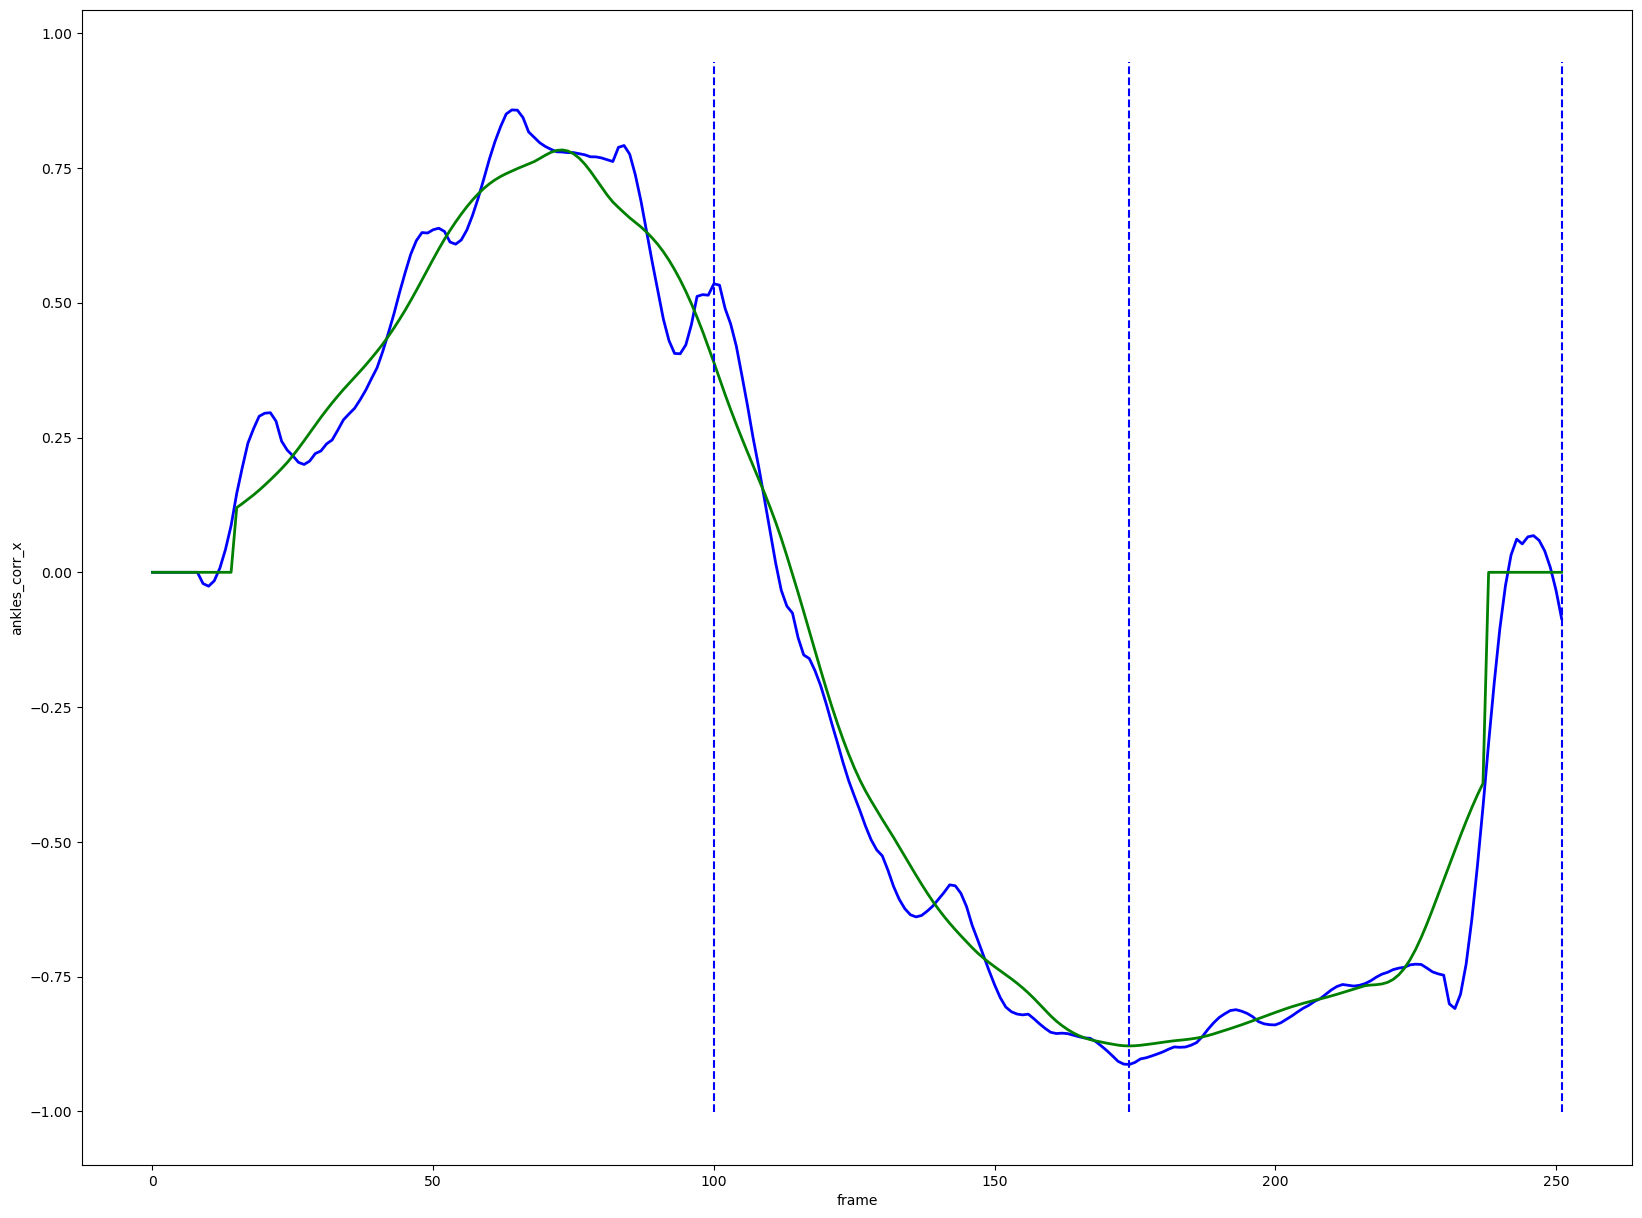

Direction: Right-to-Left (Score: -0.516)


<Figure size 2000x1500 with 0 Axes>

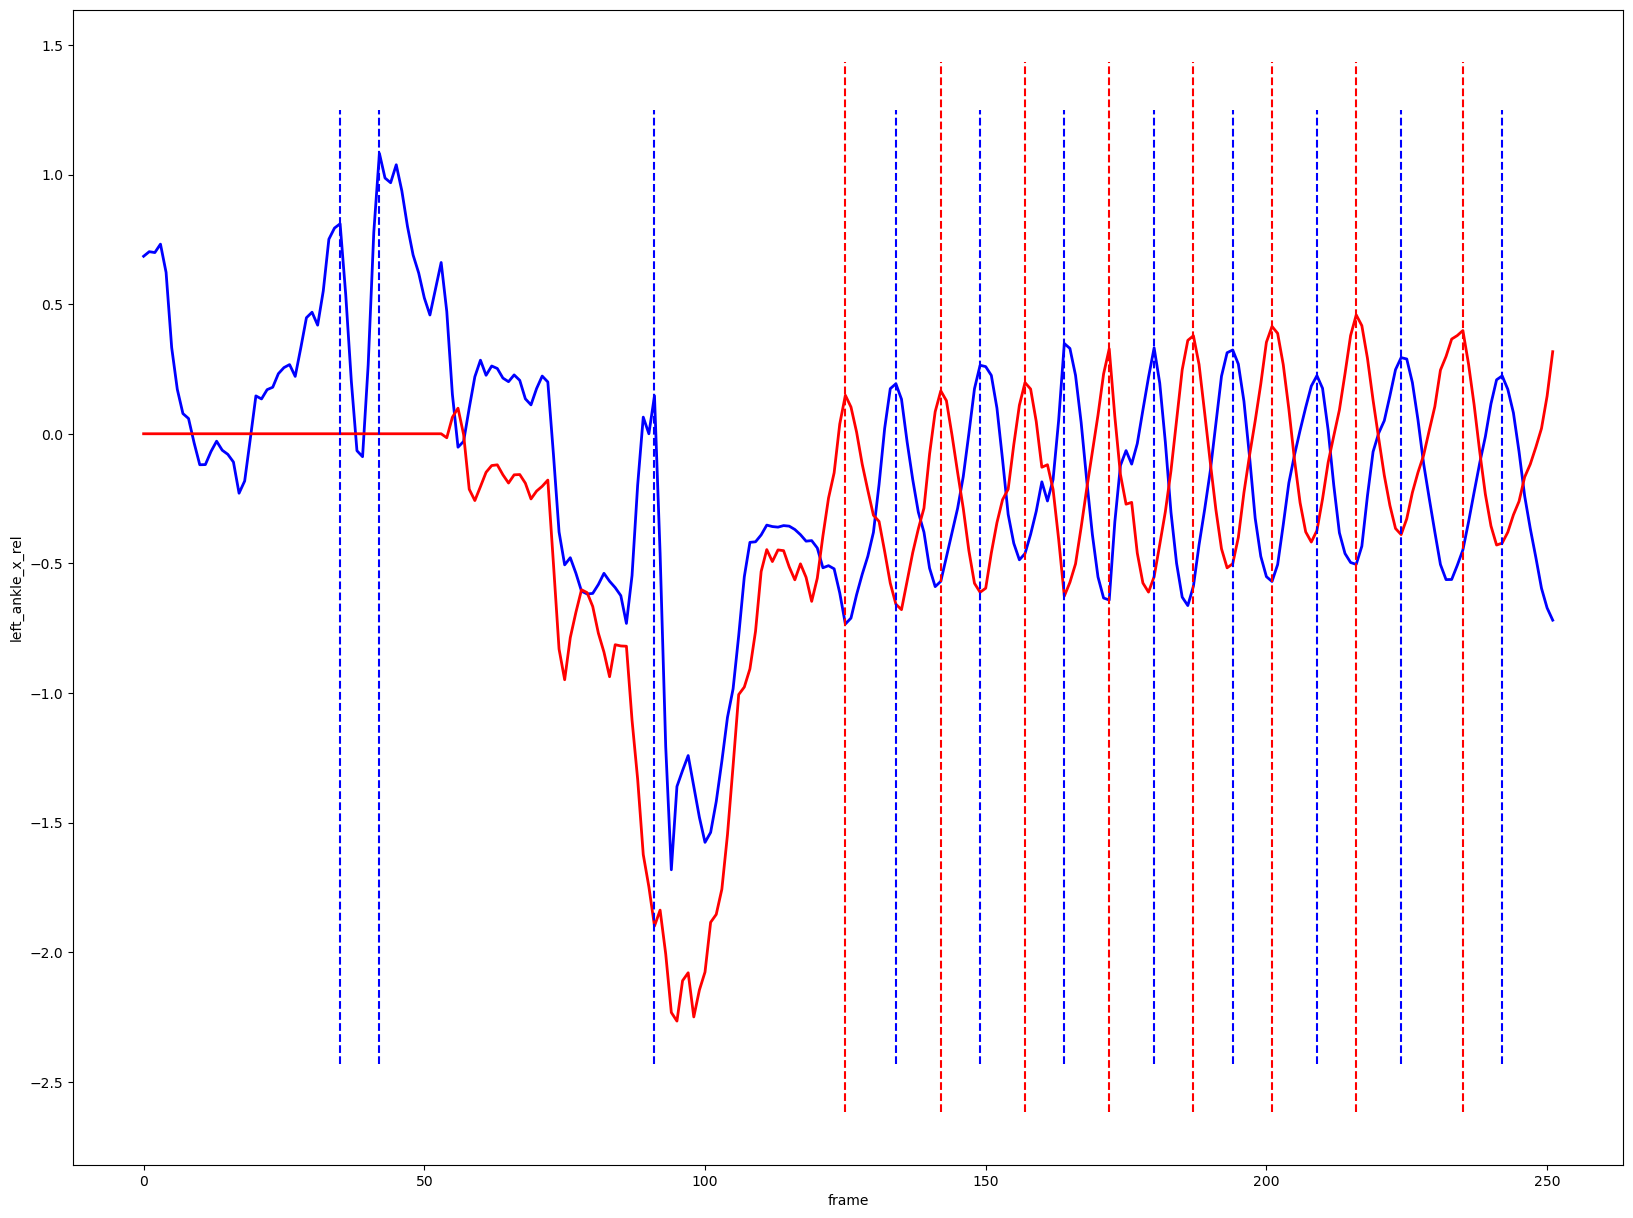

Min gap: 12. Max_gap: 27


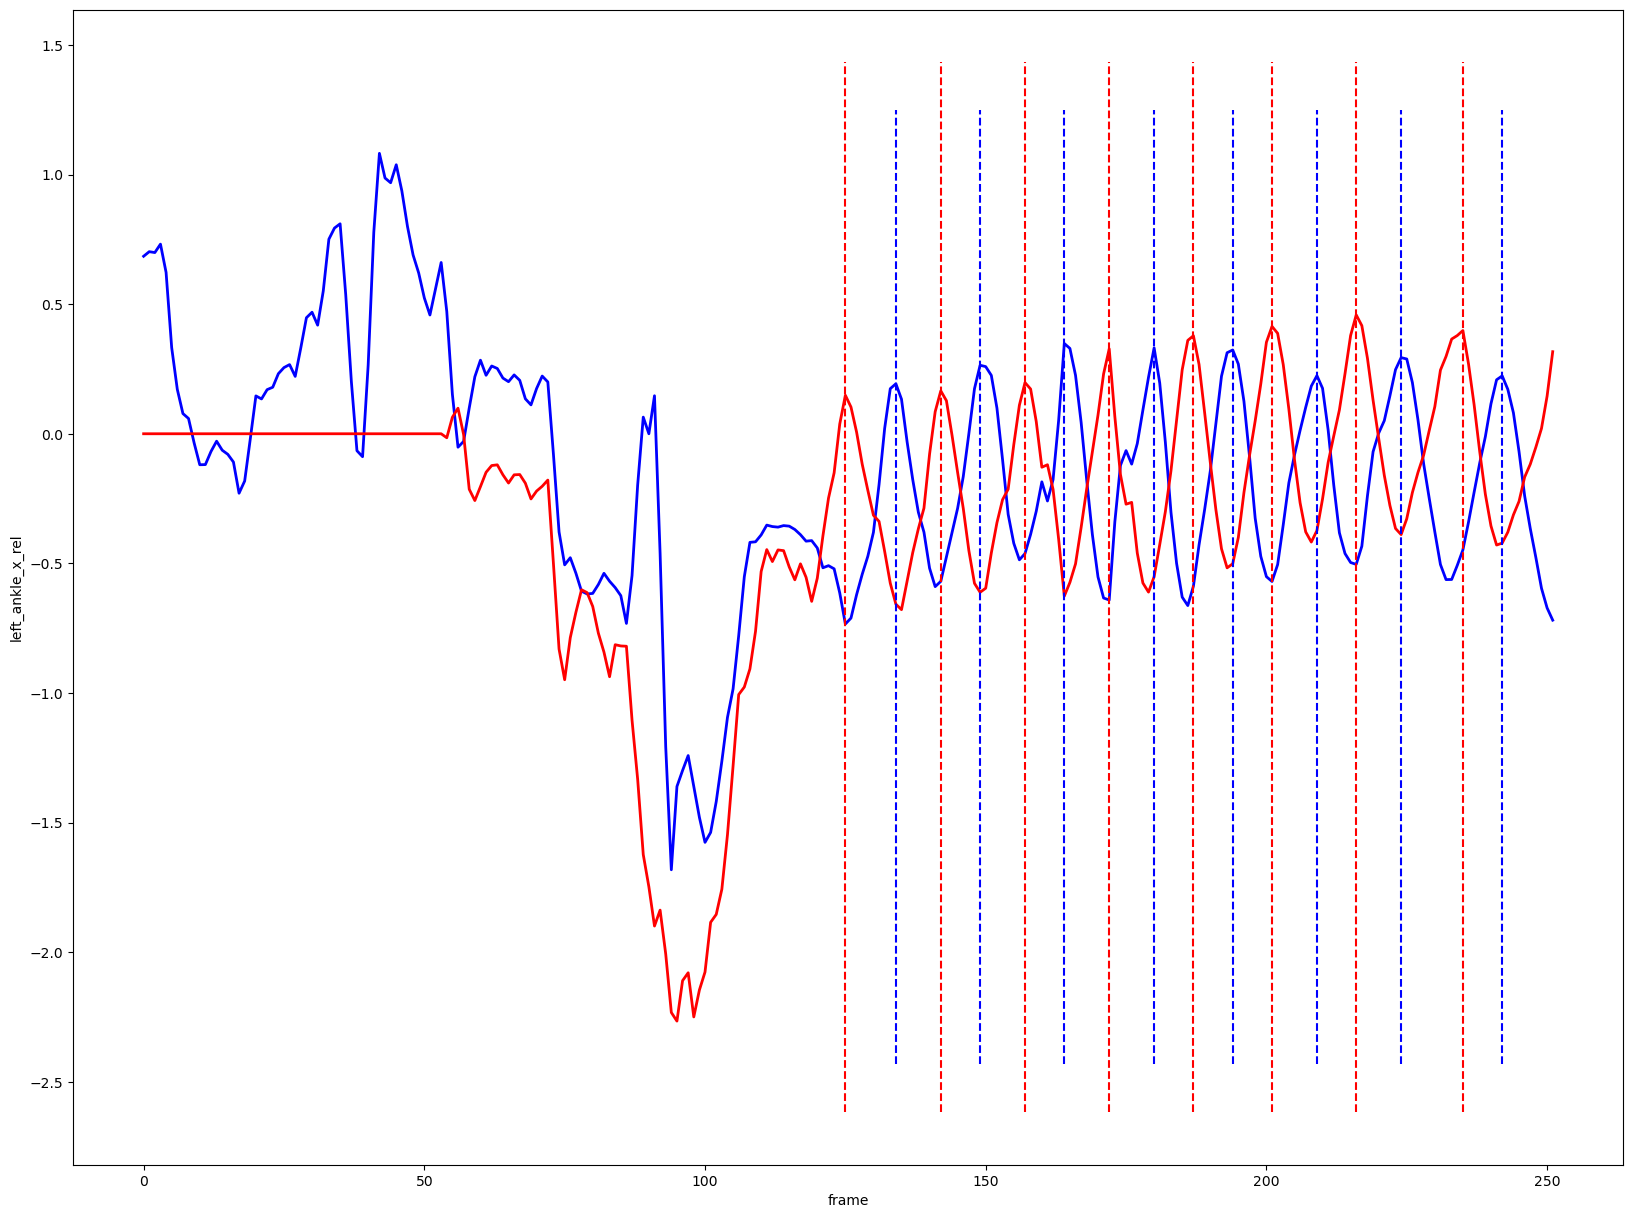

First_peak: 0
First_peak: 0


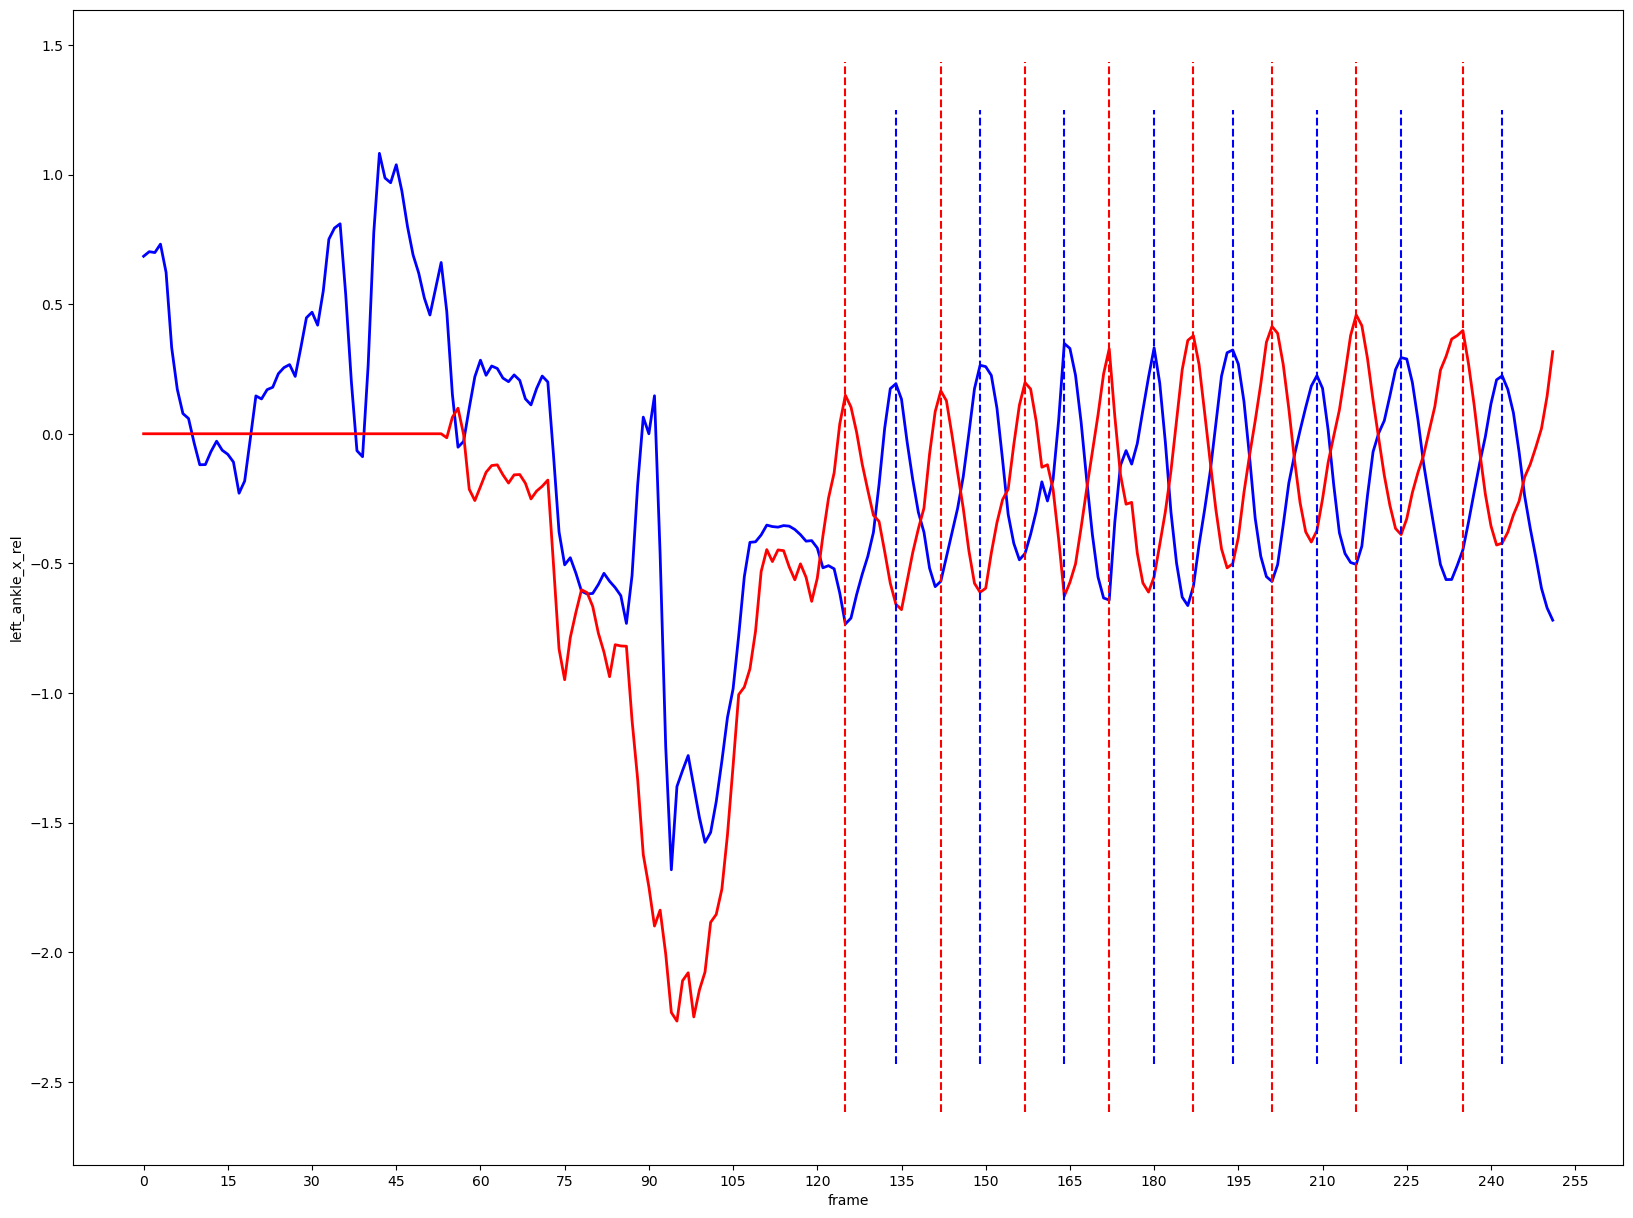

frame
0      0.000000
1      0.000000
2      0.000000
3      0.000000
4      0.000000
         ...   
247    0.059224
248    0.039483
249    0.008774
250   -0.032902
251   -0.085546
Name: ankles_corr_x, Length: 252, dtype: float64

In [90]:
import seaborn as sns
import matplotlib.pyplot as plt

athlete = Athlete(athlete_bounding_boxes_df, athlete_video_keypoints_df, athlete_id, DETECTION["minimum_movement_threshold"], video.fps)

athlete.df = athlete.df.set_index("frame", drop=False)

athlete.df["ankles_corr_x"] = athlete.CorrelationValues(ATHLETE["AnkleCorrelationWindowSize"])

# athlete.df.set_index("frame", drop=False)


approach_start, approach_end, mid_sprint, rolling_corr = detection.GetApproachBounds(athlete.df["ankles_corr_x"], ATHLETE["correlation_threshold_for_start"], ATHLETE["correlation_threshold_for_end"], ATHLETE["corr_rolling_average_scalar"], fps=athlete.fps, window_size=ATHLETE["AnkleCorrelationWindowSize"])


# print(approach_start, approach_end)

plt.figure(plt.figure(figsize=(20, 15)))
sns.lineplot(data=athlete.df, x="frame", y="ankles_corr_x", color="blue", linewidth=2)
sns.lineplot(rolling_corr, color="green", linewidth=2)

plt.vlines([approach_start, approach_end, mid_sprint], plt.ylim()[0], plt.ylim()[1], color="blue", linestyles="dashed")


plt.show()





athlete.df = athlete.df.set_index("frame", drop=False).sort_index()


direction_score = athlete.CalculateDirectionScore(ATHLETE["knee_peaks_prominence"], ATHLETE["minimum_direction_score"], approach_start, approach_end)

runningLeftToRight = True

# 4. Make the final directional decision
if direction_score > 0:
    runningLeftToRight = True
    print(f"Direction: Left-to-Right (Score: {direction_score:.3f})")
else:
    runningLeftToRight = False
    print(f"Direction: Right-to-Left (Score: {direction_score:.3f})")


if (not runningLeftToRight):
    athlete.df["left_ankle_x_rel"] *= -1
    athlete.df["right_ankle_x_rel"] *= -1






plt.figure(figsize=(20, 15))  

left_ankle_sprint = athlete.df["left_ankle_x_rel"]
right_ankle_sprint = athlete.df["right_ankle_x_rel"]

sprint_peaks_left, sprint_peaks_right = athlete.findPeaks(left_ankle_sprint, right_ankle_sprint, DETECTION["leg_extension_peak_prominence"], DETECTION["leg_extension_peak_height"])

plt.figure(figsize=(20,15))

sns.lineplot(left_ankle_sprint, color="blue", linewidth=2)
sns.lineplot(right_ankle_sprint, color="red", linewidth=2)

plt.vlines(sprint_peaks_left, plt.ylim()[0], plt.ylim()[1], color="blue", linestyles="dashed")
plt.vlines(sprint_peaks_right, plt.ylim()[0], plt.ylim()[1], color="red", linestyles="dashed")

plt.show()


min_gap = int(round(athlete.fps * DETECTION["leg_extension_min_gap"]))  
max_gap = int(round(athlete.fps * DETECTION["leg_extension_max_gap"]))

print(f"Min gap: {min_gap}. Max_gap: {max_gap}")

sprint_peaks_left = detection.FilterPeaksByApproachStartAndEnd(sprint_peaks_left, approach_start, approach_end)
sprint_peaks_right = detection.FilterPeaksByApproachStartAndEnd(sprint_peaks_right, approach_start, approach_end)


plt.figure(figsize=(20,15))

sns.lineplot(left_ankle_sprint, color="blue", linewidth=2)
sns.lineplot(right_ankle_sprint, color="red", linewidth=2)

plt.vlines(sprint_peaks_left, plt.ylim()[0], plt.ylim()[1], color="blue", linestyles="dashed")
plt.vlines(sprint_peaks_right, plt.ylim()[0], plt.ylim()[1], color="red", linestyles="dashed")

plt.show()



sprint_peaks_left = detection.filterPeaksbyTimeBetween(sprint_peaks_left, min_gap, max_gap, DETECTION["consecutive_extension_peak"])
sprint_peaks_right = detection.filterPeaksbyTimeBetween(sprint_peaks_right, min_gap, max_gap, DETECTION["consecutive_extension_peak"])





plt.figure(figsize=(20,15))


relativeXankle = sns.lineplot(left_ankle_sprint, color="blue", linewidth=2)
relativeXankle = sns.lineplot(right_ankle_sprint, color="red", linewidth=2)


plt.vlines(sprint_peaks_left, plt.ylim()[0], plt.ylim()[1], color="blue", linestyles="dashed")
plt.vlines(sprint_peaks_right, plt.ylim()[0], plt.ylim()[1], color="red", linestyles="dashed")



sprint_peaks = np.concatenate((np.array(sprint_peaks_left), np.array(sprint_peaks_right)))
sprint_peaks.sort()





relativeXankle.xaxis.set_major_locator(ticker.MultipleLocator(15))
plt.show()

athlete.df["ankles_corr_x"]



       frame  person_id_x    x1   y1    x2   y2  person_id_y     left_x  \
frame                                                                     
0          0            1  1091  444  1195  557            1  77.829361   
1          1            1  1092  444  1196  559            1  79.826515   
2          2            1  1094  445  1198  559            1  78.357895   
3          3            1  1095  445  1199  559            1  77.674980   
4          4            1  1097  445  1200  559            1  77.605034   
...      ...          ...   ...  ...   ...  ...          ...        ...   
247      247            1   833  350   910  532            1  71.969589   
248      248            1   830  349   903  531            1  71.634628   
249      249            1   826  348   894  522            1  72.464752   
250      250            1   818  346   887  522            1  74.677406   
251      251            1   811  346   878  521            1  75.735199   

           left_y    rig

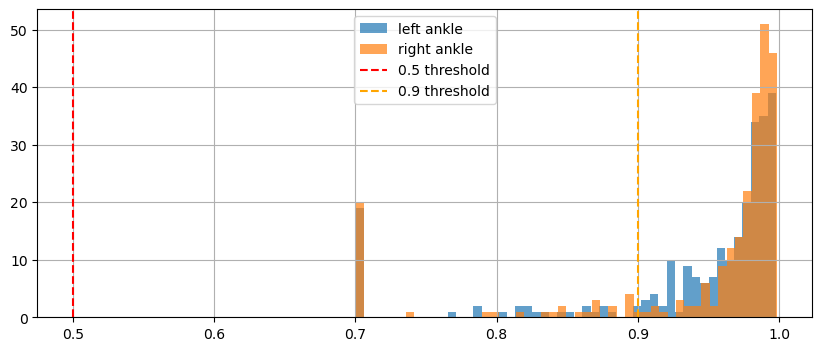

In [91]:
print(athlete.df)

plt.figure(figsize=(10, 4))
athlete.df["left_conf"].hist(bins=50, alpha=0.7, label="left ankle")
athlete.df["right_conf"].hist(bins=50, alpha=0.7, label="right ankle")
plt.axvline(0.5, color='red', linestyle='--', label='0.5 threshold')
plt.axvline(0.9, color='orange', linestyle='--', label='0.9 threshold')
plt.legend()
plt.show()

Find initial contact frames using maximum extension frames

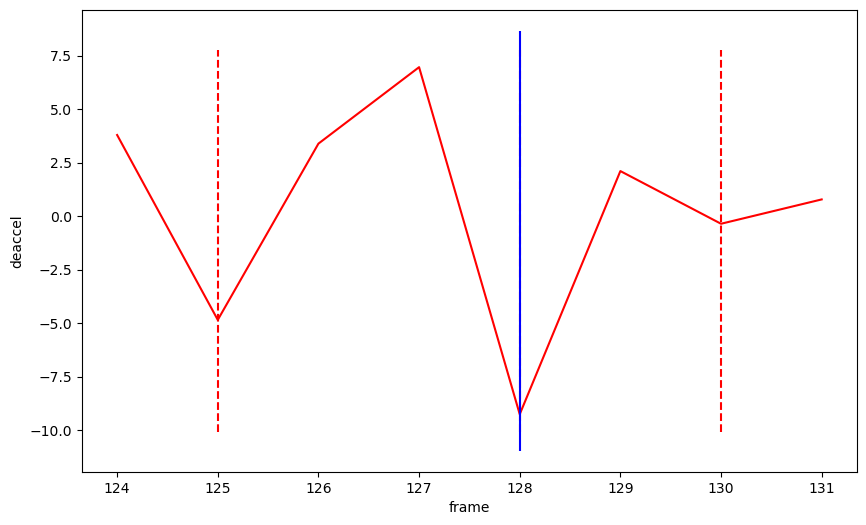

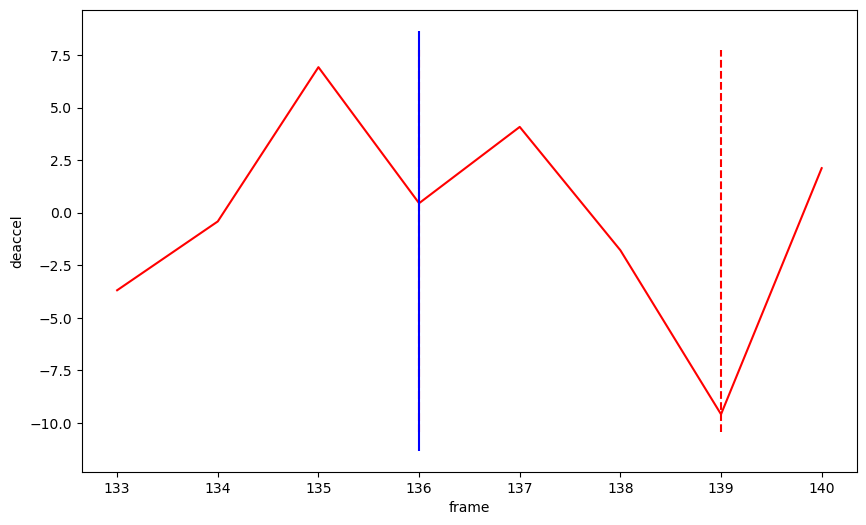

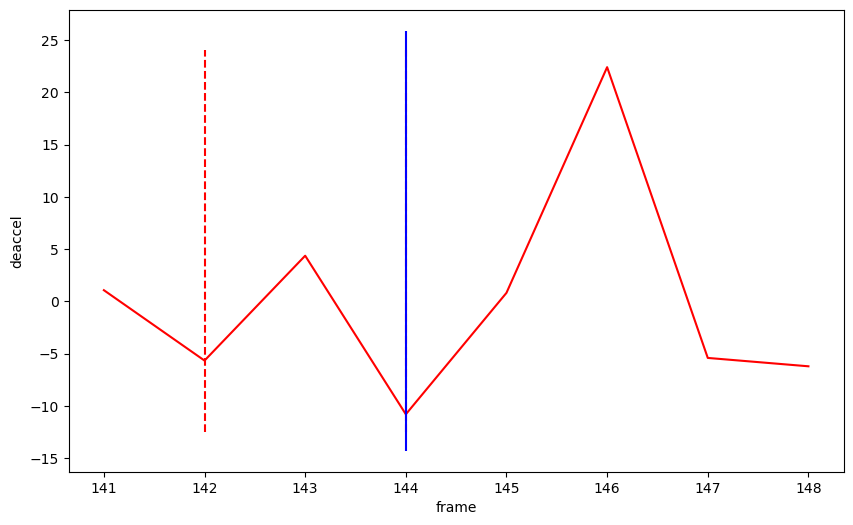

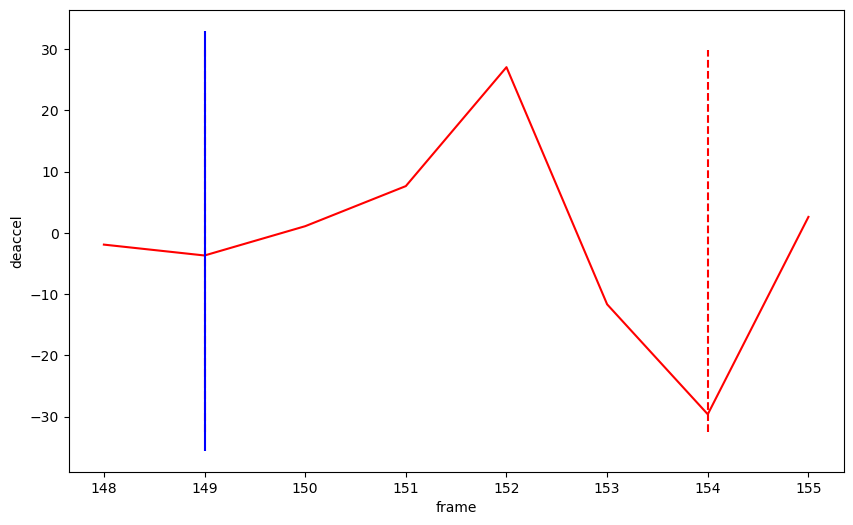

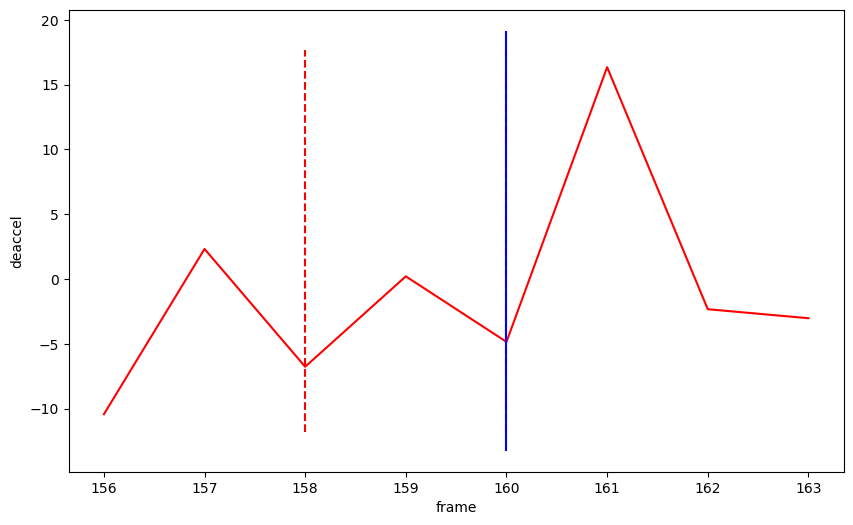

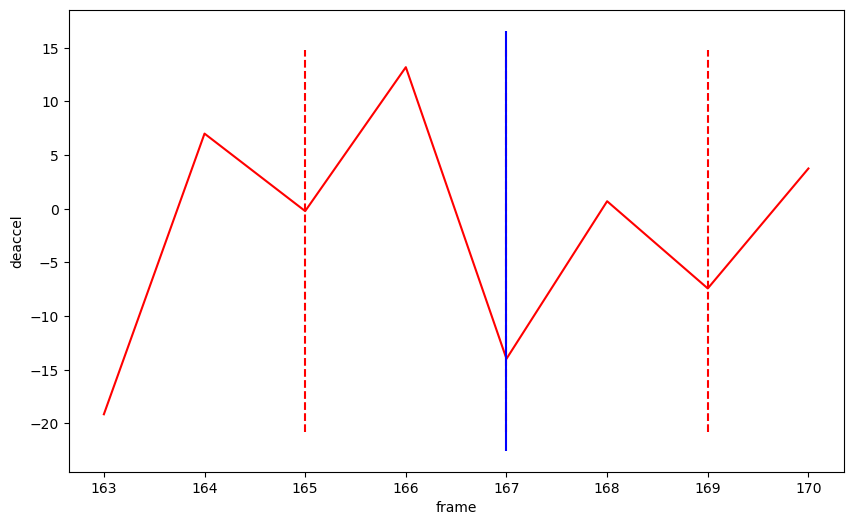

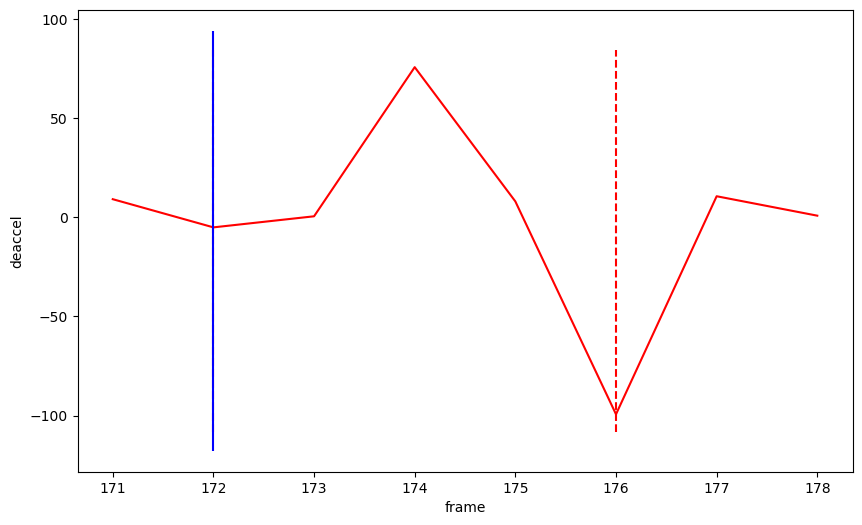

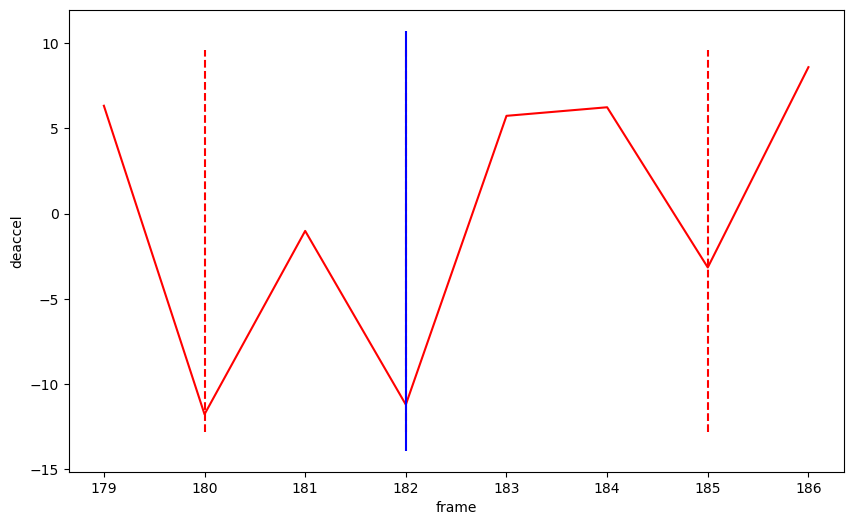

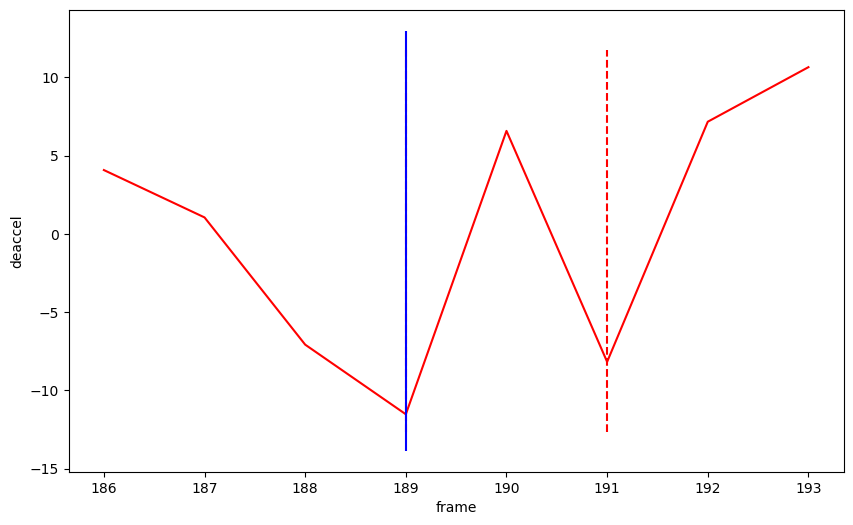

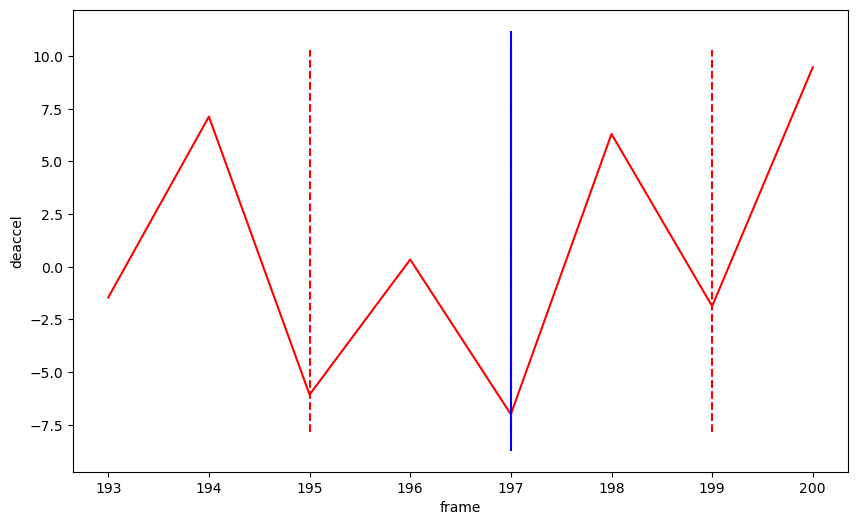

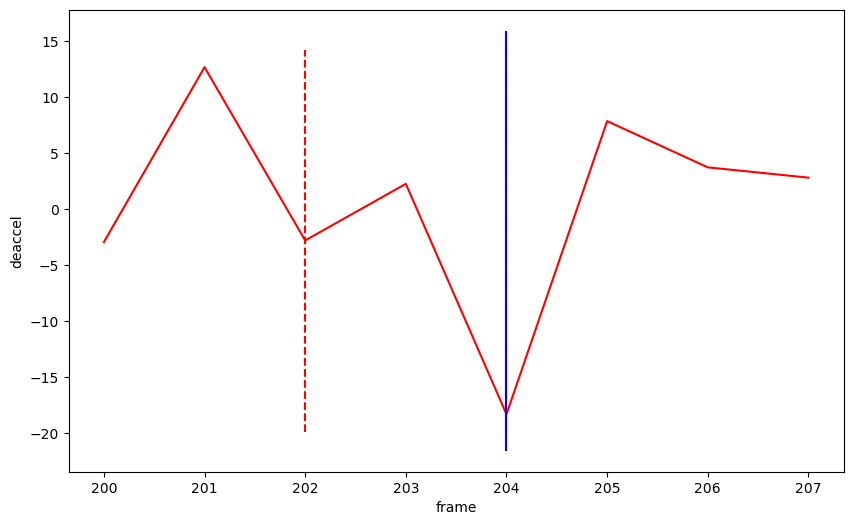

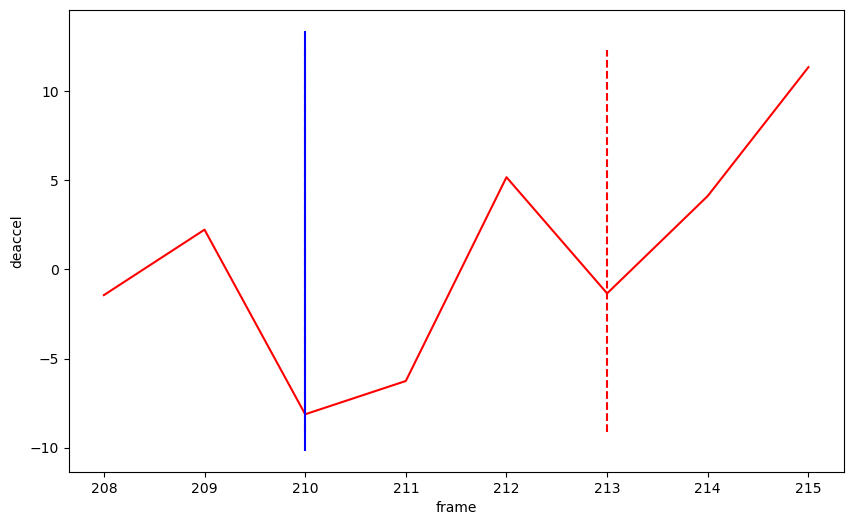

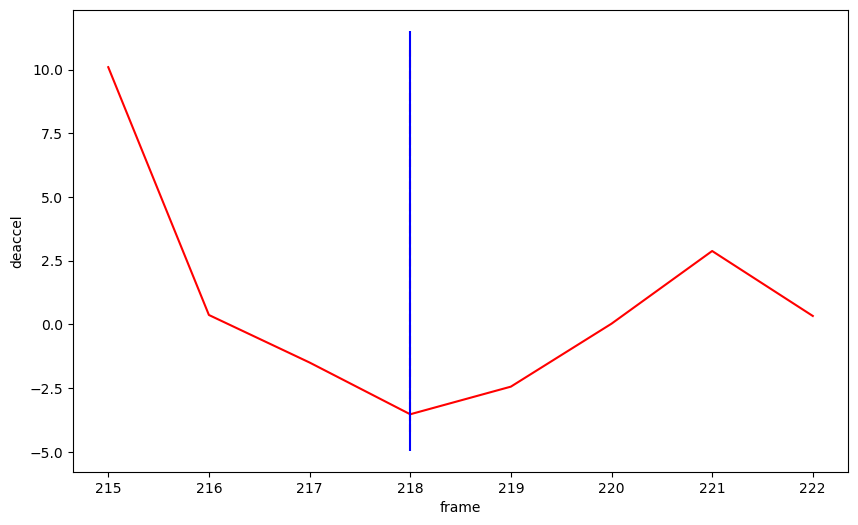

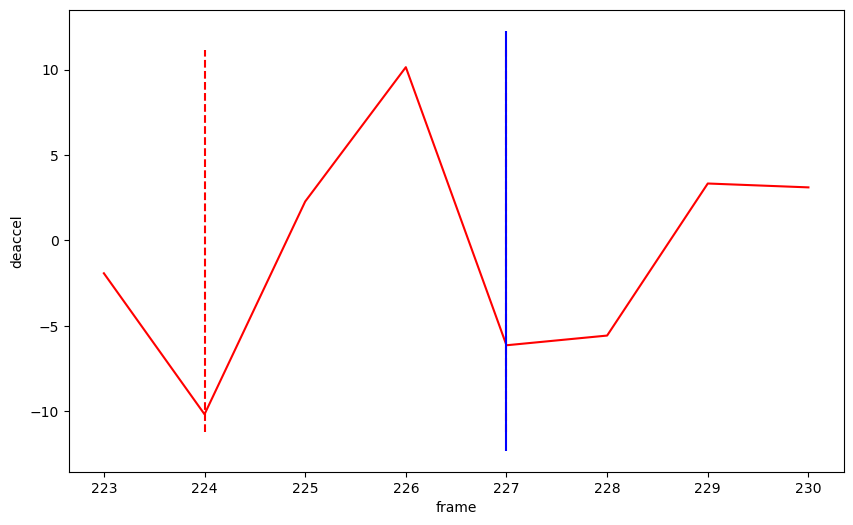

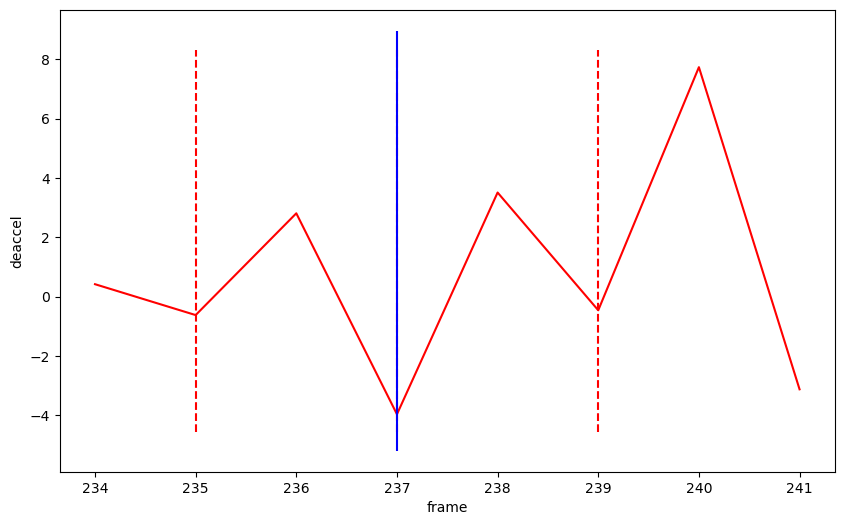

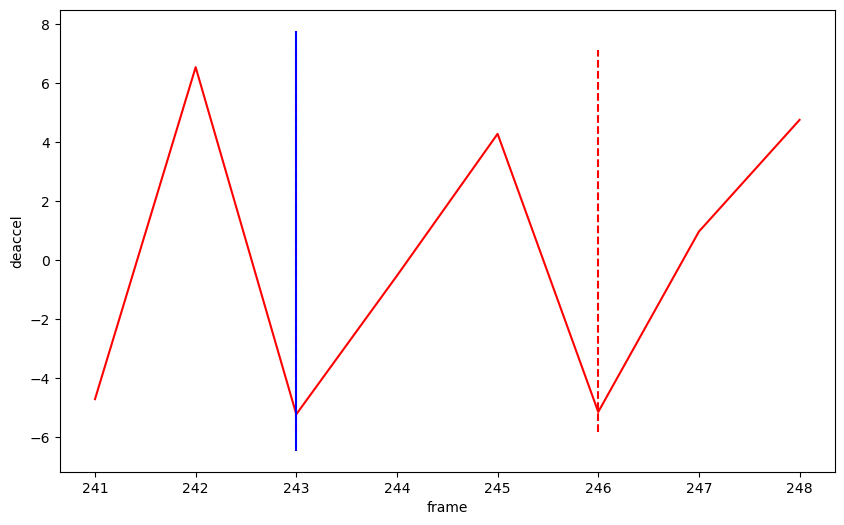

[np.int64(128), np.int64(136), np.int64(144), np.int64(149), np.int64(160), np.int64(167), np.int64(172), np.int64(182), np.int64(189), np.int64(197), np.int64(204), np.int64(210), np.int64(218), np.int64(227), np.int64(237), np.int64(243)]


In [92]:

frames_before_max_extension = int(round(video.fps *DETECTION["possible_initial_contact_frames_before_leg_extension"]))
frames_after_max_extension = int(round(video.fps * DETECTION["possible_initial_contact_frames_after_leg_extension"]))
initial_contact_frames = []

for max_extension_frame in sprint_peaks:
    isLeft = False
    if (max_extension_frame in sprint_peaks_left):
        isLeft = True
    ankle_df = athlete.GetAnkleVerticalDeacceleration(max_extension_frame, isLeft, frames_before_max_extension, frames_after_max_extension)

    plt.figure(figsize=(10, 6))

    sns.lineplot(ankle_df["deaccel"], color="red")

    peak_deaccel = find_peaks((ankle_df["deaccel"]) * -1)[0]

    detected_frames = ankle_df["frame"].iloc[peak_deaccel].values

    if (len(detected_frames) <= 0):
        # raise detection.InitialContactNotFound()
        print("No detection found, athlete most likeley took off")
        break
    else:
        candidate_rows = ankle_df[ankle_df["frame"].isin(detected_frames)]

        best_row_idx = candidate_rows["x_dist"].idxmin()

        chosen_frame = candidate_rows.loc[best_row_idx, "frame"]
        initial_contact_frames.append(chosen_frame)

    plt.vlines(detected_frames, plt.ylim()[0], plt.ylim()[1], color="red", linestyles="dashed")
    plt.vlines(initial_contact_frames[-1], plt.ylim()[0], plt.ylim()[1], color="blue", linestyles="solid")
    plt.show()
    
print(initial_contact_frames)


TAKEOFF DETECTION

Draw bounding boxes and circles on ankles (FOR TESTING)

Draw boxes on the bounding boxes (TESTING)

For each box:
Draws a green rectangle (cv2.rectangle) around the person.
Adds a green “Person” label above the box using cv2.putText.

In [93]:
# print(video_keypoints_df)

if (video is None):
    video = Video(video_path)

with video as cap:
    visualization.processVideo(cap, video, save_path, athlete_bounding_boxes_df, athlete.df, athlete_id, initial_contact_frames, sprint_peaks, sprint_peaks_left)


Save output in save_path

In [94]:
print(f"Output image saved to {save_path}")

Output image saved to d:\Users\ekrik\Codes\JumpAproachGraphed\SavedJumpVideos\Acceleration4.mp4


d:\Users\ekrik\Codes\JumpAproachGraphed\CorrectOutput\Acceleration4.csv
Estimated Ground contacts:  [128, 136, 144, 149, 160, 167, 172, 182, 189, 197, 204, 210, 218, 227, 237, 243]


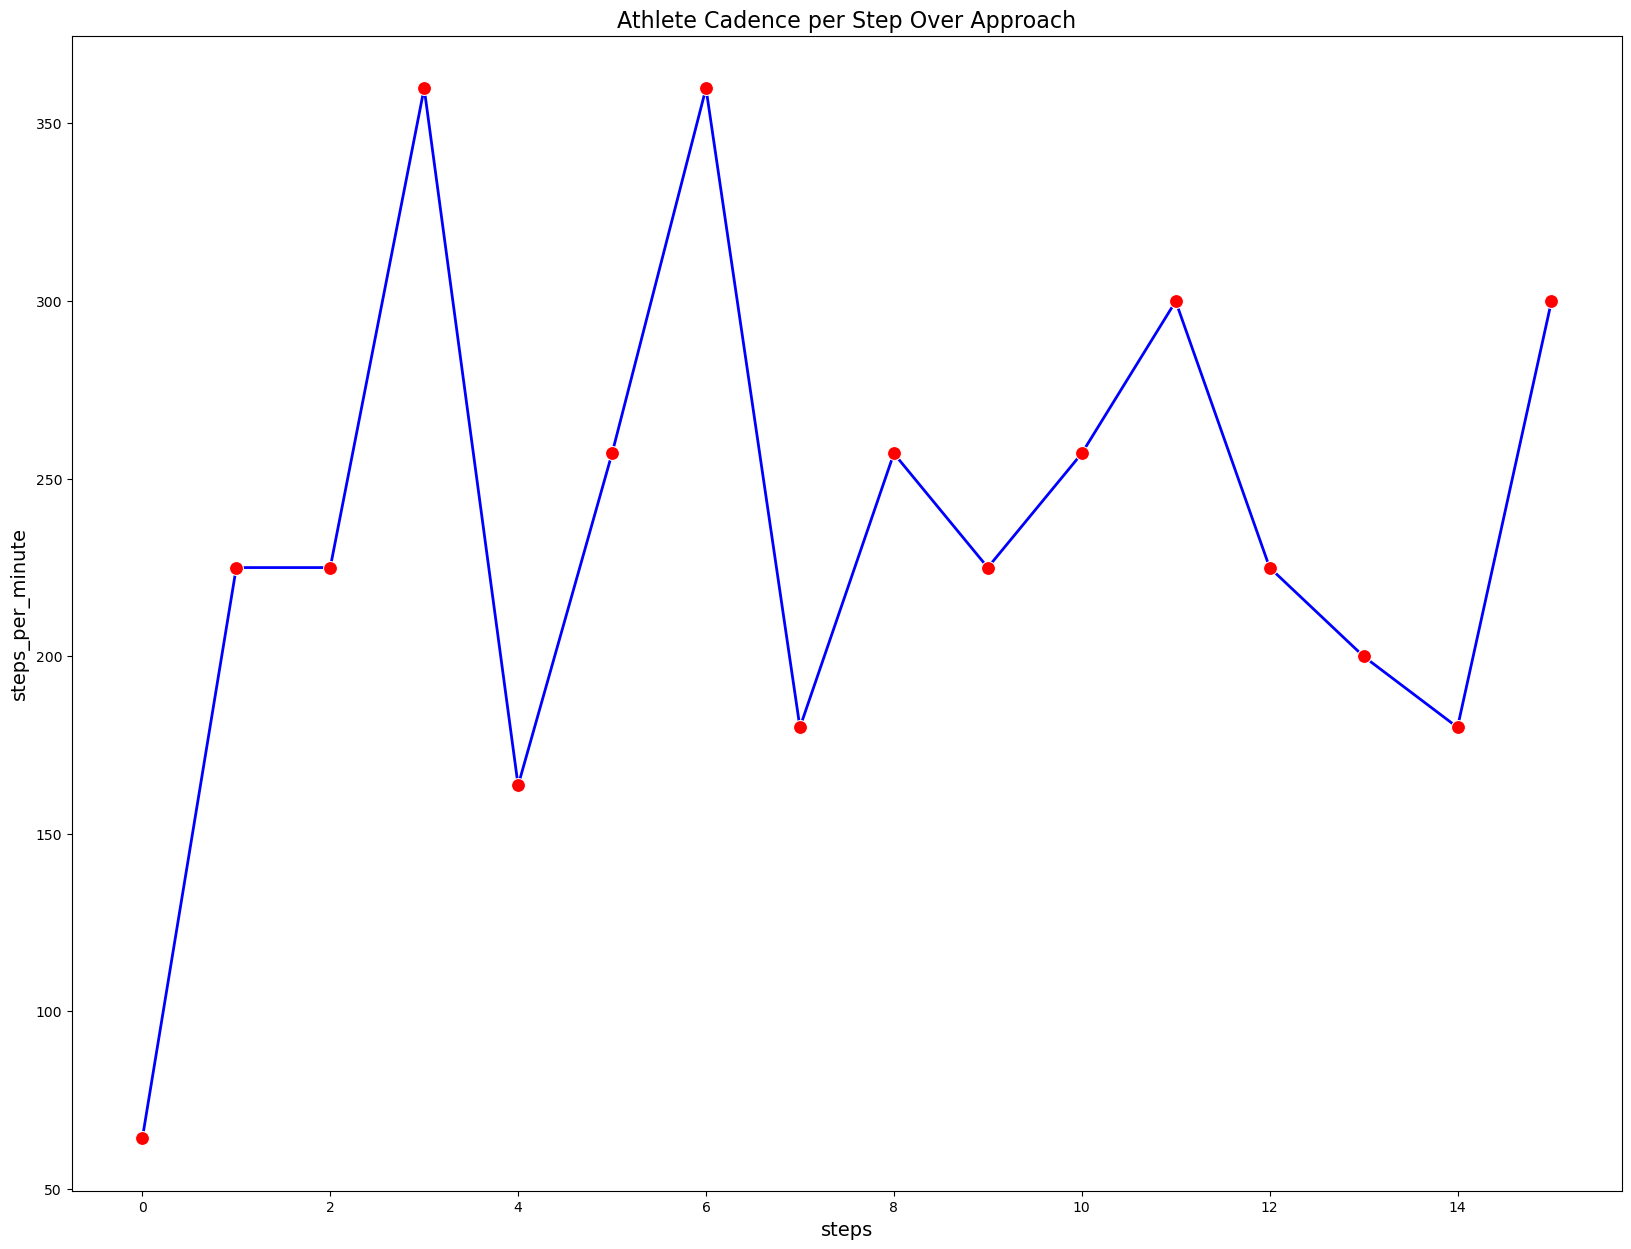

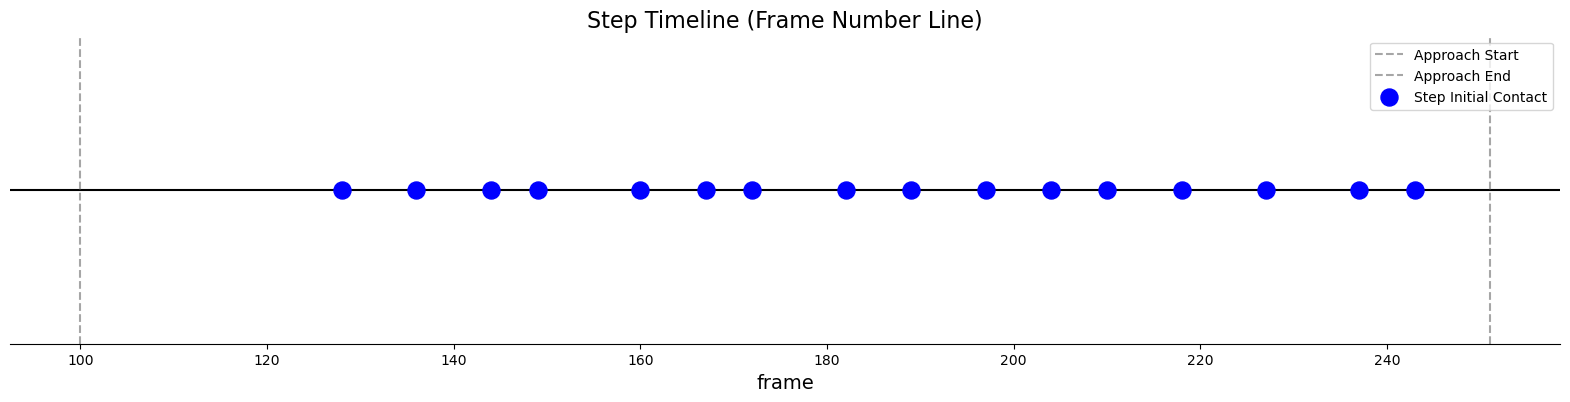

In [95]:
import csv
from pathlib import Path


correct_contacts = []

print(str(ROOT / PATHS["correct_output"] / (videoName + ".csv")))


file_path = Path(str(ROOT / PATHS["correct_output"] / (videoName + ".csv")))
if file_path.is_file():

    with open(str(ROOT / PATHS["correct_output"] / (videoName + ".csv")), mode='r', newline='') as file:
        # Use DictReader to access fields by column headers
        for line in file:
            # Split by comma and strip whitespace
            parts = line.split(',')
            for ground_contact in parts:
                correct_contacts.append(int(ground_contact.strip()))

    print("Correct Ground contacts: ", correct_contacts)

new_initial_contact_frames = []
for frame in initial_contact_frames:
    new_initial_contact_frames.append(int(frame))

print("Estimated Ground contacts: ", new_initial_contact_frames)

strides_per_minute = []
for stride in range(0, len(new_initial_contact_frames)):
    if (stride == 0):
        stride_time = new_initial_contact_frames[0] - approach_start
    else:
        stride_time = new_initial_contact_frames[stride] - new_initial_contact_frames[stride-1]
    
    strides_per_minute.append((athlete.fps*60) / stride_time) # 1 second / time each stride takes to get strides per second

plt.figure(figsize=(20,15))
sns.lineplot(strides_per_minute, color="blue", linewidth=2, marker="o", markersize=10, markerfacecolor="red")

plt.xlabel("steps", fontsize=14)
plt.ylabel("steps_per_minute", fontsize=14)
plt.title("Athlete Cadence per Step Over Approach", fontsize=16)        
plt.gca().xaxis.set_major_locator(ticker.MaxNLocator(integer=True))     

plt.show()



plt.figure(figsize=(20, 4)) # Wide and short to look like a literal number line

# 1. Plot the approach start as a dashed reference line
plt.axvline(x=approach_start, color="gray", linestyle="--", alpha=0.7, label="Approach Start")
plt.axvline(x=approach_end, color="gray", linestyle="--", alpha=0.7, label="Approach End")


# 2. Plot each step frame as a dot on a flat line (y=0 for all points)
y_zeros = [0] * len(new_initial_contact_frames)
plt.scatter(
    x=new_initial_contact_frames, 
    y=y_zeros, 
    color="blue", 
    s=150,                 # Size of the dots
    zorder=3,              # Ensures dots sit on top of the axis line
    label="Step Initial Contact"
)

# 3. Draw a solid baseline across the span of the frames
plt.axhline(y=0, color="black", linewidth=1.5, zorder=1)

# 4. Clean up the styling to make it look like a pure timeline
plt.xlabel("frame", fontsize=14)
plt.title("Step Timeline (Frame Number Line)", fontsize=16)

# Hide the Y-axis entirely since it has no meaning here
plt.gca().get_yaxis().set_visible(False)

# Remove the top, left, and right border lines of the plot box
sns.despine(left=True, top=True, right=True, bottom=False)

# Add a legend to explain the dashed line and dots
plt.legend(loc="upper right")

plt.show()

